In [37]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
from windrose import WindroseAxes
import foxes
import foxes.variables as FV
from pathlib import Path
import importlib, nowake_analysis as ta
importlib.reload(ta)

<module 'nowake_analysis' from 'c:\\Users\\HP\\Desktop\\Python_Modeling_and_Analysis_for_Wind_Energy\\python-wind-project\\nowake_analysis.py'>

In [38]:
df = pd.read_csv('reanalysis/reanalysis_2006.csv')
print(df.head())

             Date_time  WS100  WD100
0  2006-01-01 00:00:00  8.515  243.1
1  2006-01-01 01:00:00  8.379  246.2
2  2006-01-01 02:00:00  7.772  245.6
3  2006-01-01 03:00:00  7.852  241.6
4  2006-01-01 04:00:00  8.319  239.5


In [39]:
dt_index = pd.to_datetime(df["Date_time"], utc=True)
df = df.set_index(dt_index)
df.index.name = "Date_time"
df = df.sort_index()
df = df.drop(columns=["Date_time"])
print(df.head())

                           WS100  WD100
Date_time                              
2006-01-01 00:00:00+00:00  8.515  243.1
2006-01-01 01:00:00+00:00  8.379  246.2
2006-01-01 02:00:00+00:00  7.772  245.6
2006-01-01 03:00:00+00:00  7.852  241.6
2006-01-01 04:00:00+00:00  8.319  239.5


In [40]:
print(len(df) - (365*24))

0


In [41]:
print(np.sum(df.index.duplicated()))

0


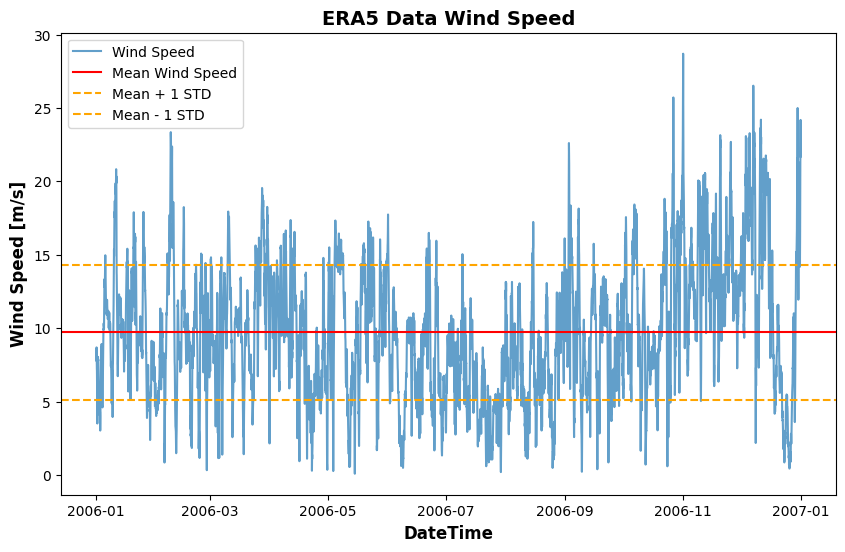

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(df['WS100'], label="Wind Speed", alpha=0.7) 
plt.title("ERA5 Data Wind Speed", fontsize=14, fontweight="bold")
mean_ws = df['WS100'].mean()
std_ws = df['WS100'].std()
plt.axhline(mean_ws, color='red', label="Mean Wind Speed")
plt.axhline(mean_ws + std_ws, color='orange', linestyle='--', label="Mean + 1 STD")
plt.axhline(mean_ws - std_ws, color='orange', linestyle='--', label="Mean - 1 STD")
plt.xlabel("DateTime", fontsize=12, fontweight="bold")
plt.ylabel("Wind Speed [m/s]", fontsize=12, fontweight="bold")
plt.legend() 
plt.show()

----

**Observed Wind Speed Pattern**: As shown in the plot above, the wind speed ranges from nearly 0 m/s to a maximum of about 29 m/s, with a mean wind speed of about 10 m/s and a standard deviation of around 5 m/s. The minimum wind speed occurred within May - August, reaching near 0 m/s, while the months of November and December have the highest wind speeds reaching nearly 30 m/s.

----

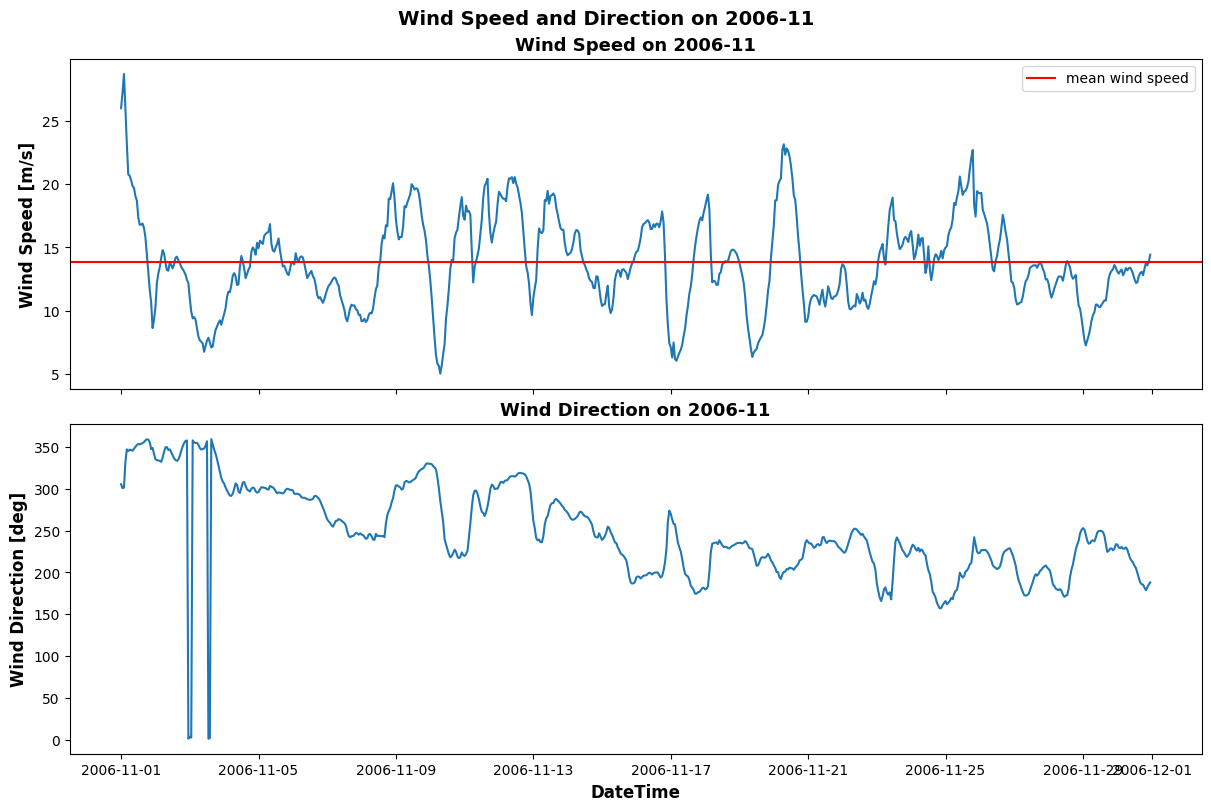

In [44]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
ax[0].plot(df['WS100'].loc["2006-11"])
ax[0].set_ylabel("Wind Speed [m/s]", fontsize=12, fontweight="bold")
ax[0].set_title("Wind Speed on 2006-11", fontsize=13, fontweight="bold")
ax[0].axhline(df['WS100'].loc["2006-11"].mean(), label="mean wind speed", color="red")

ax[1].plot(df['WD100'].loc["2006-11"])
ax[1].set_ylabel("Wind Direction [deg]", fontsize=12, fontweight="bold")
ax[1].set_title("Wind Direction on 2006-11", fontsize=13, fontweight="bold")
ax[1].set_xlabel("DateTime", fontsize=12, fontweight="bold")

fig.suptitle("Wind Speed and Direction on 2006-11", fontsize=14, fontweight="bold")
ax[0].legend()
plt.show()

In [45]:
df['WS100'].loc["2006-11"].describe()

count    720.000000
mean      13.828128
std        3.622398
min        5.038000
25%       11.296250
50%       13.489500
75%       16.183500
max       28.697000
Name: WS100, dtype: float64

----
A zoomed in overview of the wind speed and direction in the month of November indicates that an average wind speed of about 14 m/s reaching reaching 29 m/s maximum and lowest wind speeds of 5 m/s and std of 4 m/s.

Furthermore, the wind direction for this month shows the wind is dominated the Northwest sector, reaching nearly 300 degrees

----

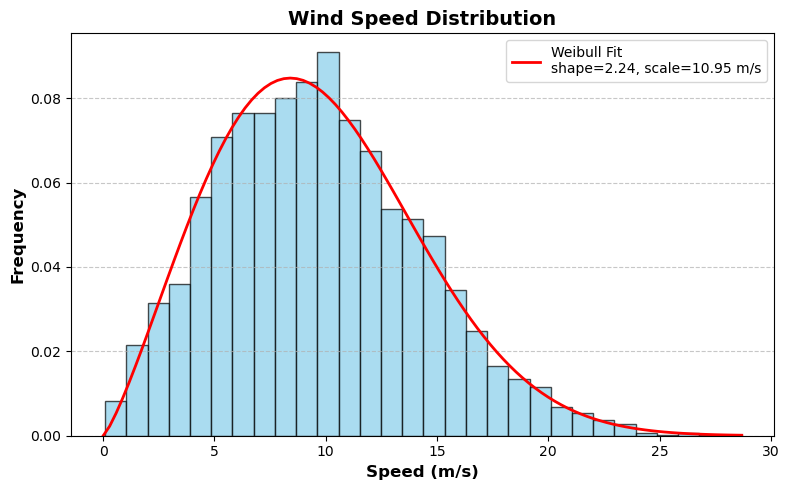

In [7]:
shape, loc, scale = stats.weibull_min.fit(df['WS100'], floc=0)

plt.figure(figsize=(8, 5))
plt.hist(df['WS100'], bins=30, density=True, color='skyblue', edgecolor='black', alpha=0.7)

x = np.linspace(0, max(df['WS100']), 100)
plt.plot(x, stats.weibull_min.pdf(x, shape, loc, scale), 'r-', lw=2, label=f'Weibull Fit\nshape={shape:.2f}, scale={scale:.2f} m/s')

plt.title('Wind Speed Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Speed (m/s)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

----


- The scale parameter is directly proportional to the mean wind speed of the site. It indicates how "windy" the location is. A Weilbull distribution scale parameter value of 10.95 m/s for this site$ is exceptionally high. 

- Because available wind power scales with the cube of the wind speed ($v^3$), a site with a scale parameter near 11 m/s will have a massive Wind Power Density (WPD), making it highly lucrative for energy generation.

- The shape parameter value of $k = 2.24$ indicates a distribution that is slightly more "peaked" or narrow than average. This implies that  wind speed at this site is highly consistent.


**The high consistency** ($k = 2.24$) coupled with the high mean speed means a turbine placed here will operate at its rated power capacity for a large percentage of the year. This makes grid integration and energy yield forecasting highly predictable.

**Structural Loads**: Because the wind speeds are tightly clustered around the optimal generation range (8 to 12 m/s) with fewer extreme high-wind events, the turbine will experience a steadier aerodynamic thrust. This consistency reduces the extreme cyclic fatigue loading on the turbine blades and supporting offshore structures, which is a highly favorable profile for maximizing the service life extension of the assets.

----

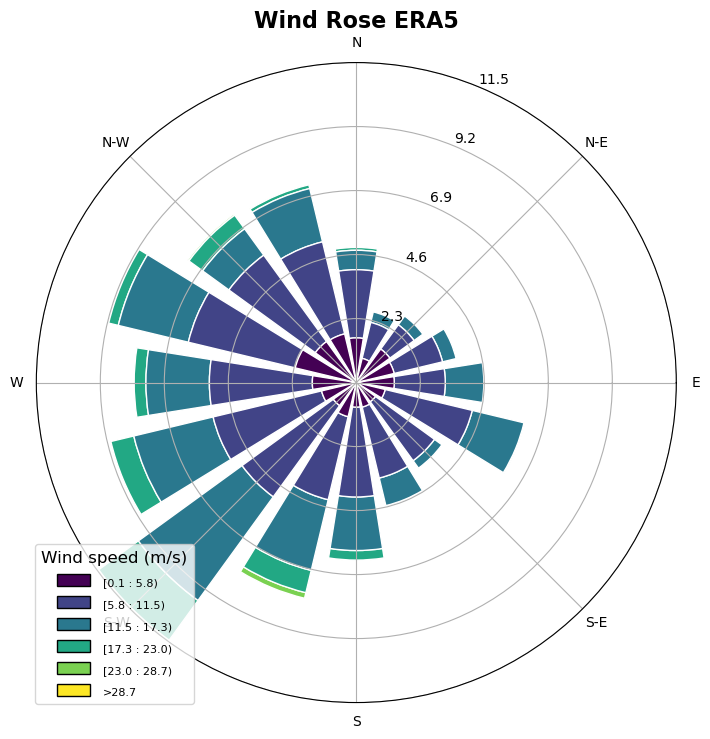

In [8]:
fig = plt.figure(figsize=(8, 8))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    df['WD100'],
    df['WS100'],
    normed=True,
    opening=0.8,
    edgecolor="white"
)

ax.set_legend(title="Wind speed (m/s)", fontsize=12, title_fontsize=12)
ax.set_title("Wind Rose ERA5",fontsize=16, fontweight="bold")
plt.show()

----

An analysis of the windrose indicates indicates the Southwest and Northwest sectors  as the dominant wind sector with the Southwest having having a larger share. This means the Southwest will have the highest energy contribution, followed by the Northwest, while the Northeast takes a 3rd place.

----

# Task 3: Yield of the Areas N-10.1/N-10.2 Without External Wake Effects

In [34]:
#===============================================================
# Step 1: Load ERA5 Data as States
#===============================================================
latitude = 54.602
longitude = 6.145
states = foxes.input.states.Timeseries(
    data_source = Path("reanalysis/reanalysis_2006.csv"),
    output_vars = [FV.WS, FV.WD, FV.TI, FV.RHO],
    var2col={FV.WS: "WS100", FV.WD: "WD100"},
    fixed_vars={FV.TI: 0.05, FV.RHO: 1.225},  
  # log-law extrapolation to hub height 
    read_pars={"dayfirst": True}
)

#================================================================
# Step 2: Set Up turbine type
#================================================================
mbook = foxes.ModelBook()
mbook.turbine_types["IEA15MW"] = foxes.models.turbine_types.PCtFile(
    Path("./turbine-info/power_curves/IEA-15MW-D240-H150.csv").resolve(strict=True),
    col_ws="ws", 
    col_P="P",
    col_ct="ct",
    D=240.0,
    H=150.0,
    P_nominal=15000,
    P_unit="kW",
    rho=1.225
)
#================================================================
# Step 3-5: Compute farm results
#================================================================
def compute_farm(farm_layout, states, mbook, farm_name):
    """Compute the farm results for a given layout and states.
        Parameters:
        -----------
        farm_layout: str
            Path to the CSV file containing the farm layout (columns: x, y).
        states: foxes.input.states.Timeseries
            The input states containing the meteorological data.
        mbook: foxes.ModelBook
            The model book containing turbine definitions and other models.
        farm_name: str
            A name for the wind farm (used for identification in outputs).
        Returns:
        --------
        results: foxes.output.FarmResults
            The computed results for the wind farm.
        farm: foxes.WindFarm
            The wind farm object containing turbine information and layout.
        algorithm: foxes.algorithms.Downwind
            The algorithm object used for the farm calculation.
    """
    #--------------------------------------------------------------------
    # step 3: Wind Farm Layout
    #--------------------------------------------------------------------
    farm = foxes.WindFarm(name=farm_name)
    
    foxes.input.farm_layout.add_from_file(
        farm,
        farm_layout,
        col_x="x",
        col_y="y",
        turbine_models=["IEA15MW"],
        verbosity=0
    )

    #----------------------------------------------------------------
    # Step 4: Algorithm setup for no wake models
    #----------------------------------------------------------------
    algorithm = foxes.algorithms.Downwind(
        farm,
        states,
        wake_models=[],
        mbook=mbook,
        verbosity=0
    )

    #----------------------------------------------------------------
    # Step 5: Run the foxes
    #----------------------------------------------------------------
    engine = foxes.Engine.new("process", chunk_size_states=500)
    with engine:
        results = algorithm.calc_farm()
    return results



ProcessEngine: Calculating 8760 states for 133 turbines
ProcessEngine: Starting calculation using 3 workers, for 18 states chunks.


  0%|          | 0/18 [00:00<?, ?it/s]

ProcessEngine: Completed all 18 chunks


  YIELD SUMMARY — N-10.1
  Number of turbines      : 133
  Turbine yield (annual)  :
    Min  : 79.94 GWh
    Max  : 79.94 GWh
    Mean : 79.94 GWh
  Total farm yield/year   : 10632.19 GWh
  Mean farm power         : 1213.72 MW
  Rated Farm Capacity          : 1995 MW
  Capacity Factor         : 60.8 %
  Full Load Hours         : 5329.4 



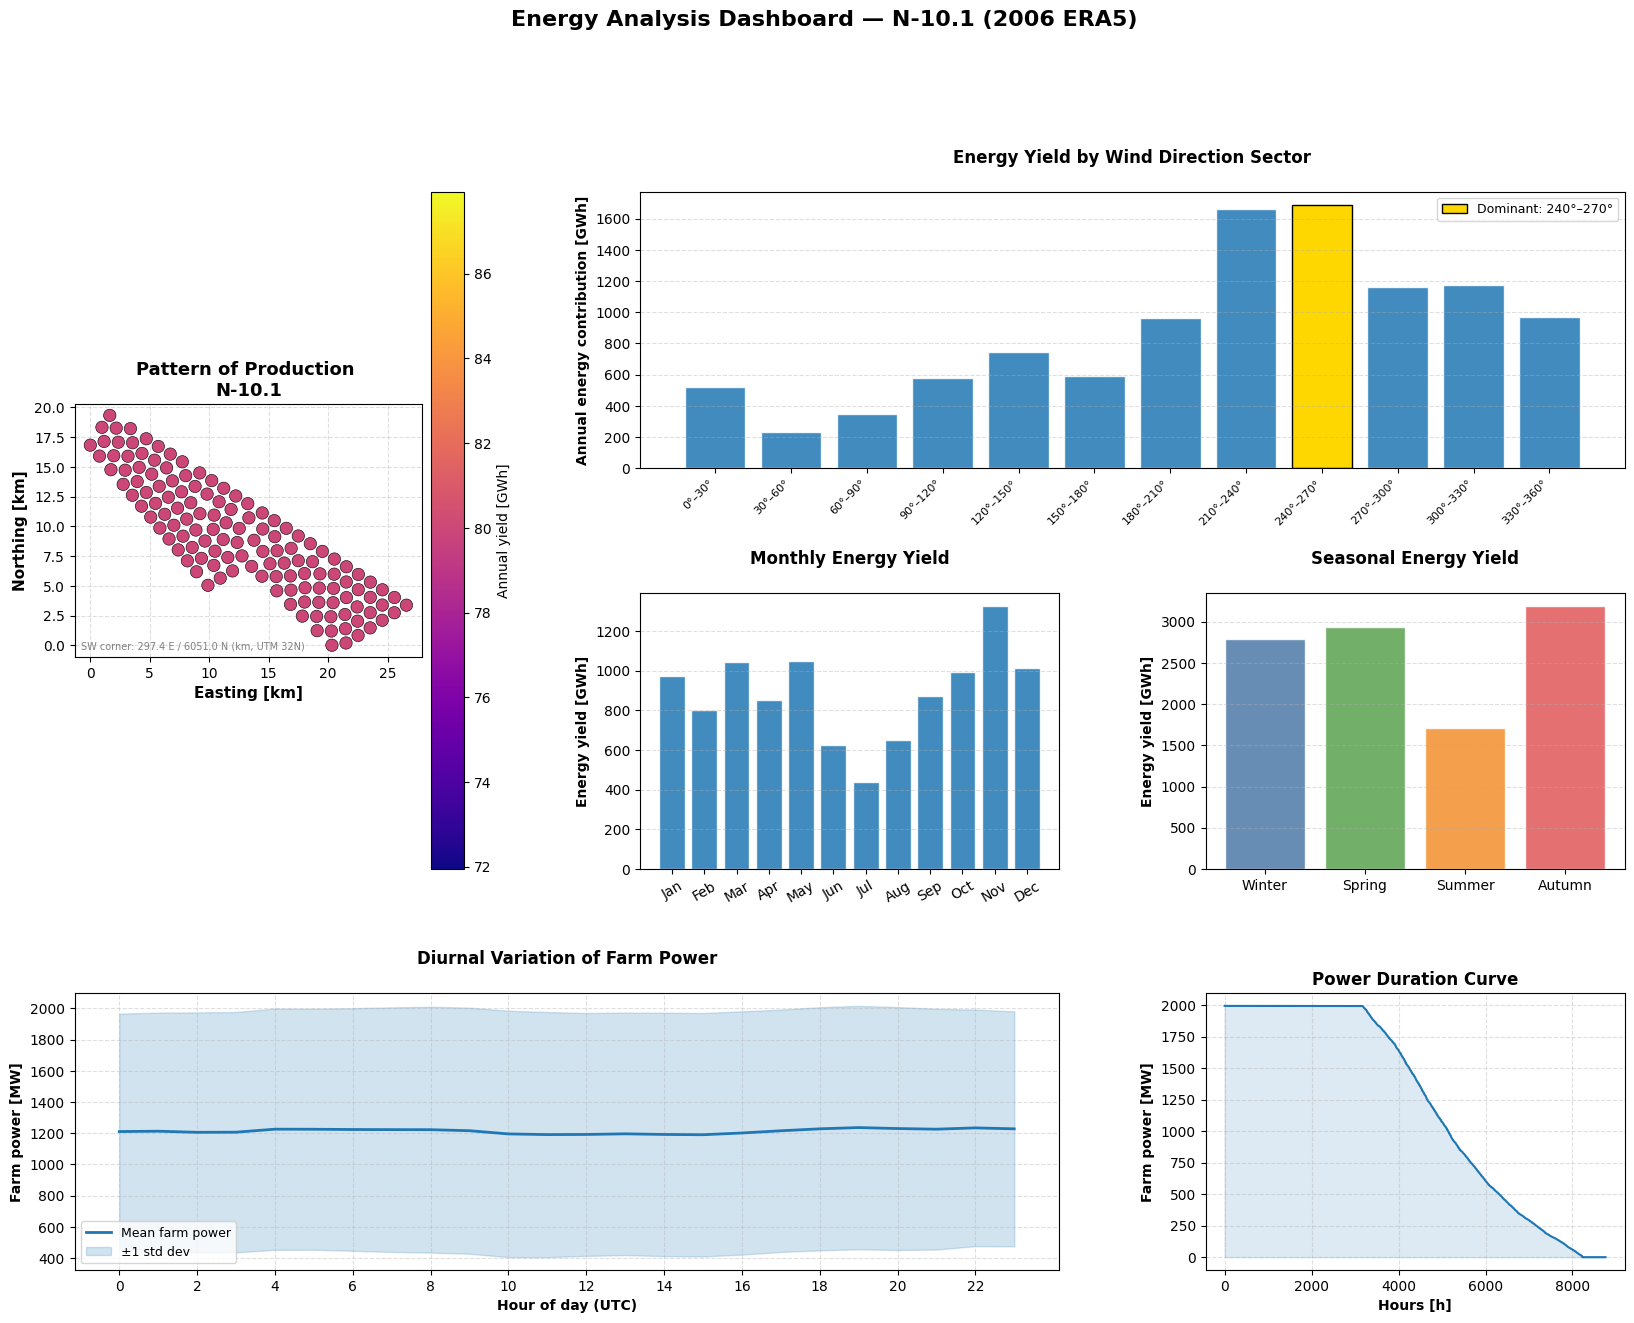

ProcessEngine: Calculating 8760 states for 33 turbines
ProcessEngine: Starting calculation using 3 workers, for 18 states chunks.


  0%|          | 0/18 [00:00<?, ?it/s]

ProcessEngine: Completed all 18 chunks


  YIELD SUMMARY — N-10.2
  Number of turbines      : 33
  Turbine yield (annual)  :
    Min  : 79.94 GWh
    Max  : 79.94 GWh
    Mean : 79.94 GWh
  Total farm yield/year   : 2638.06 GWh
  Mean farm power         : 301.15 MW
  Rated Farm Capacity          : 495 MW
  Capacity Factor         : 60.8 %
  Full Load Hours         : 5329.4 



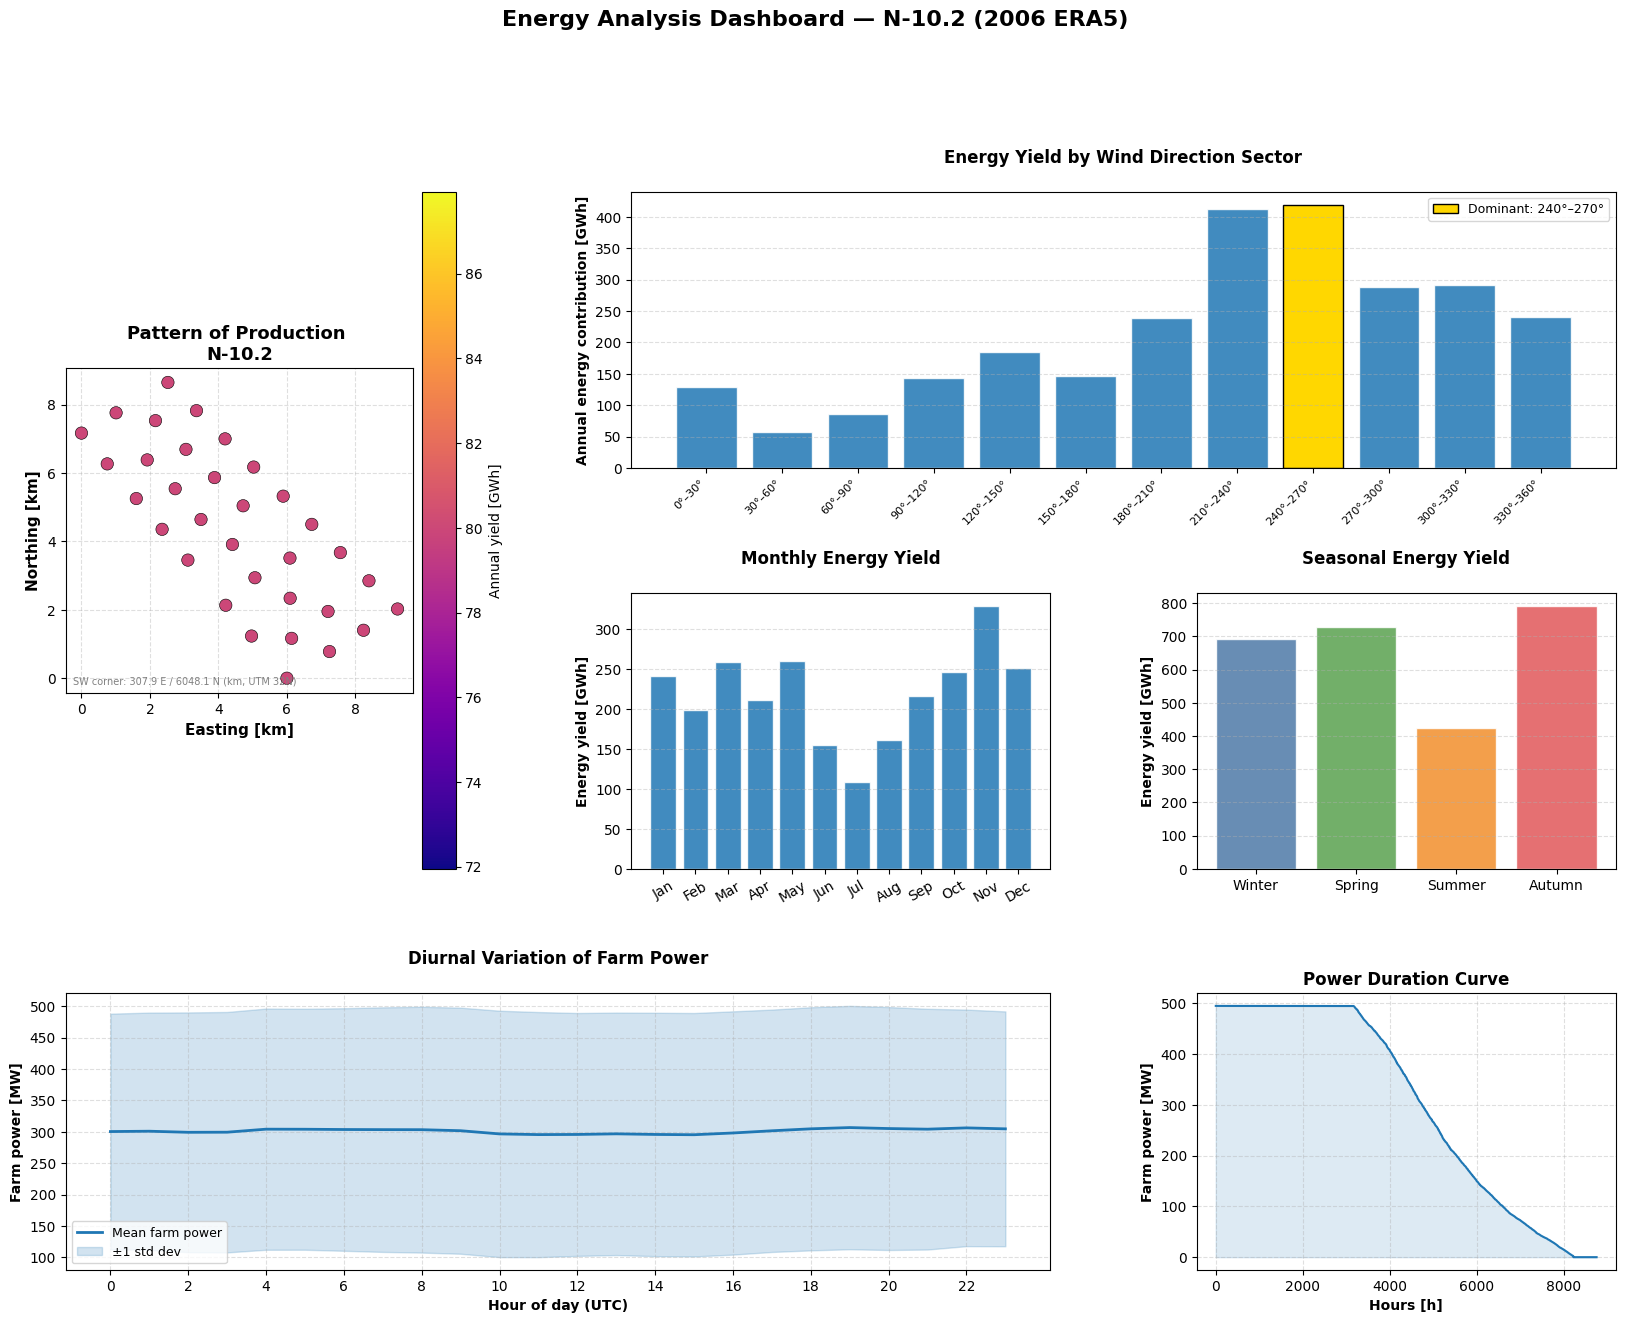

In [35]:
# ------------------------------------------------------------
# Layout paths
# ------------------------------------------------------------
farms = ["N-10.1", "N-10.2"]

layout_paths = {
    "N-10.1": Path("./turbine-info/area_of_interest/layout-N-10.1.geom.csv").resolve(strict=True),
    "N-10.2": Path("./turbine-info/area_of_interest/layout-N-10.2.geom.csv").resolve(strict=True),
}


for farm_name in farms:
    farm_layout = layout_paths[farm_name]
    results = compute_farm(farm_layout, states, mbook, farm_name)
    result_df = ta.prepare_results_df(results)
    ta.print_yield_summary(result_df, farm_name)
    ta.plot_full_dashboard(result_df, farm_name)

### Task 3: No-Wake Energy Yield Analysis for N-10.1 and N-10.2

The no-wake simulation was carried out for the two areas of interest, N-10.1 and N-10.2, using the 2006 ERA5 wind data and the 15 MW reference turbine. In this scenario, no internal or external wake effects are considered, so all turbines experience the same undisturbed inflow conditions.

- For **N-10.1**, the layout contains **133 turbines**, giving a total installed capacity of **1995 MW**. The annual yield is **10632.19 GWh/year**, with a mean farm power of **1213.72 MW**. Each turbine produces approximately **79.94 GWh/year**, and the capacity factor is **60.8%**, corresponding to **5329.4 full-load hours**.

- For **N-10.2**, the layout contains **33 turbines**, giving a total installed capacity of **495 MW**. The annual yield is **2638.06 GWh/year**, with a mean farm power of **301.15 MW**. The per-turbine yield is also **79.94 GWh/year**, with the same capacity factor of **60.8%** and **5329.4 full-load hours**.

- The equal per-turbine yield in both layouts is expected. Since this is a no-wake case, all turbines use the same wind resource and the same power curve, so there is no spatial variation in production caused by wake deficits. Therefore, the total farm yield mainly scales with the number of turbines. N-10.1 produces about four times more energy than N-10.2 because it has about four times more turbines.

- The spatial pattern-of-production plots confirm this behavior: turbine production is nearly uniform within each layout. The directional analysis shows that the largest energy contribution comes from the **240°–270° wind direction sector**, while the seasonal analysis shows higher production in autumn, winter, and spring, and lower production during summer. The diurnal variation is weak, which is reasonable for an offshore wind site where daily heating effects are less dominant than over land.

Overall, the no-wake results provide the theoretical reference yield for the two areas. These values will be used as the baseline for estimating internal and external wake losses later tasks 4.

----

In [11]:
#ta.run_full_analysis(results1, results2)

In [36]:
nc_paths = ["farm_results_50km.nc", "farm_results_all.nc"]
farm_name = "AOI"

farms = ["N-10 (50km)", "N-10 (full)"]

nc_paths = {
    "N-10 (50km)": Path("farm_results_50km.nc").resolve(strict=True),
    "N-10 (full)": Path("farm_results_all.nc").resolve(strict=True),
}

for farm_name in farms:
    result_df = ta.prepare_results_nc(nc_paths[farm_name])
    ta.print_yield_summary(result_df, farm_name)
    ta.plot_full_dashboard(result_df, farm_name)

FileNotFoundError: [WinError 2] The system cannot find the file specified: 'c:\\Users\\HP\\Desktop\\Python_Modeling_and_Analysis_for_Wind_Energy\\python-wind-project\\farm_results_50km.nc'